# Bài 2: Wideband và Narrowband Spectrogram

Notebook dùng `speech.wav` gồm hai từ **“no stop”** của cùng một người nói:

- “no” cung cấp đoạn nguyên âm kéo dài;
- “stop” chứa các phụ âm bật /t/ và /p/;
- file mono, 16 kHz, dài khoảng 2,2 giây, không có nhạc nền.

Mục tiêu là so sánh cửa sổ **5 ms** và **50 ms** để quan sát sự đánh đổi giữa độ phân giải thời gian và tần số.

In [1]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

AUDIO_PATH = 'speech.wav'
TARGET_SR = 16000

y, sr = librosa.load(AUDIO_PATH, sr=TARGET_SR, mono=True)
duration = len(y) / sr

print(f'File: {AUDIO_PATH}')
print(f'Sample rate: {sr} Hz')
print(f'Số sample: {len(y)}')
print(f'Thời lượng: {duration:.2f} giây')
display(Audio(y, rate=sr))

D:\DuyToan\Python\DUT_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


File: speech.wav
Sample rate: 16000 Hz
Số sample: 35200
Thời lượng: 2.20 giây


## 1. Chuyển millisecond sang sample và tính Power Spectrogram

In [2]:
def milliseconds_to_samples(milliseconds, sample_rate):
    return int(milliseconds * sample_rate / 1000)


def calculate_power_spectrogram(signal, sr, window_ms):
    win_length = milliseconds_to_samples(window_ms, sr)
    hop_length = win_length // 4

    n_fft = 1
    while n_fft < win_length:
        n_fft *= 2

    stft = librosa.stft(
        signal,
        n_fft=n_fft,
        hop_length=hop_length,
        win_length=win_length,
        window='hann',
        center=False
    )
    power = np.abs(stft) ** 2
    power_db = librosa.power_to_db(power, ref=np.max)

    return power_db, win_length, hop_length, n_fft


wideband_db, wide_win, wide_hop, wide_n_fft = calculate_power_spectrogram(
    y, sr, window_ms=5
)
narrowband_db, narrow_win, narrow_hop, narrow_n_fft = calculate_power_spectrogram(
    y, sr, window_ms=50
)

print('=== WIDEBAND SPECTROGRAM ===')
print(f'Window 5 ms  = {wide_win} samples')
print(f'Hop          = {wide_hop} samples ({1000 * wide_hop / sr:.2f} ms)')
print(f'n_fft        = {wide_n_fft}, frequency bins = {wideband_db.shape[0]}')
print(f'Số frame     = {wideband_db.shape[1]}')
print(f'Độ rộng tần số hiệu dụng ≈ {sr / wide_win:.1f} Hz')

print('\n=== NARROWBAND SPECTROGRAM ===')
print(f'Window 50 ms = {narrow_win} samples')
print(f'Hop          = {narrow_hop} samples ({1000 * narrow_hop / sr:.2f} ms)')
print(f'n_fft        = {narrow_n_fft}, frequency bins = {narrowband_db.shape[0]}')
print(f'Số frame     = {narrowband_db.shape[1]}')
print(f'Độ rộng tần số hiệu dụng ≈ {sr / narrow_win:.1f} Hz')

=== WIDEBAND SPECTROGRAM ===
Window 5 ms  = 80 samples
Hop          = 20 samples (1.25 ms)
n_fft        = 128, frequency bins = 65
Số frame     = 1754
Độ rộng tần số hiệu dụng ≈ 200.0 Hz

=== NARROWBAND SPECTROGRAM ===
Window 50 ms = 800 samples
Hop          = 200 samples (12.50 ms)
n_fft        = 1024, frequency bins = 513
Số frame     = 171
Độ rộng tần số hiệu dụng ≈ 20.0 Hz


## 2. Hiển thị Waveform, Wideband và Narrowband Spectrogram

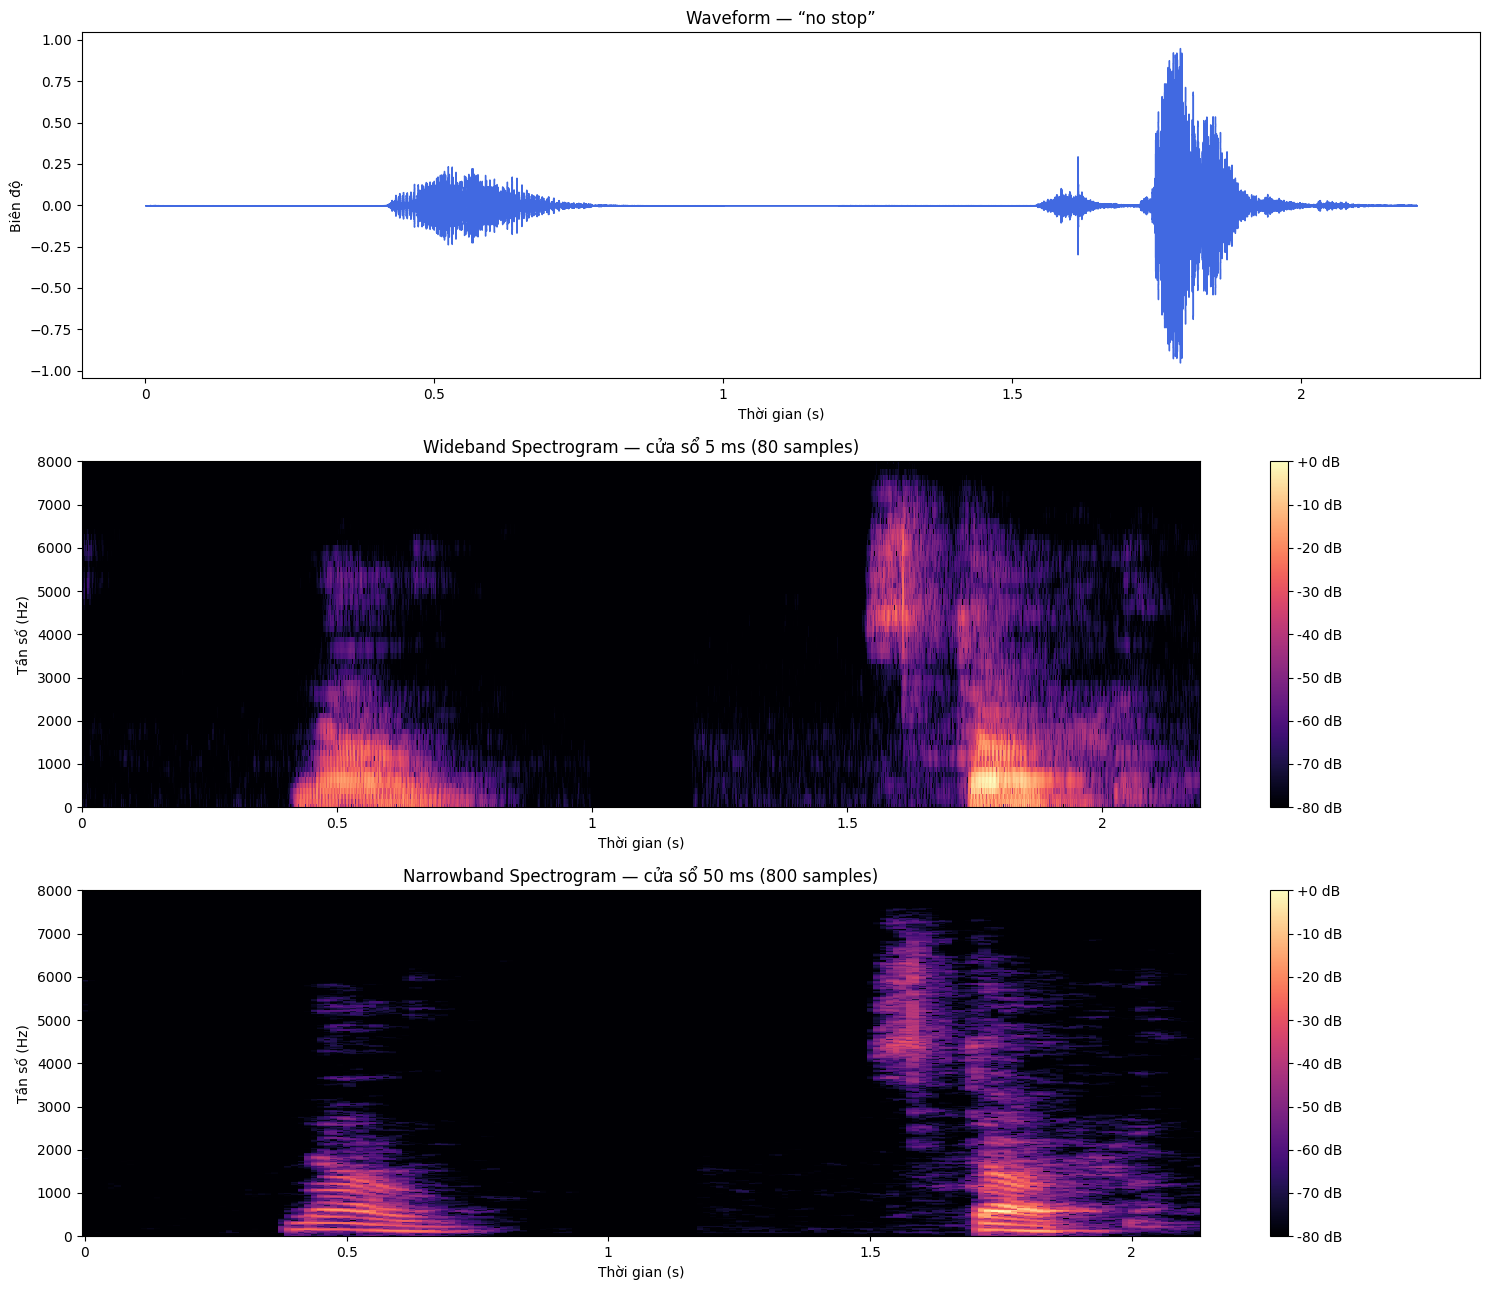

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13))

librosa.display.waveshow(y, sr=sr, ax=axes[0], color='royalblue')
axes[0].set_title('Waveform — “no stop”')
axes[0].set_xlabel('Thời gian (s)')
axes[0].set_ylabel('Biên độ')

img1 = librosa.display.specshow(
    wideband_db,
    sr=sr,
    hop_length=wide_hop,
    n_fft=wide_n_fft,
    x_axis='time',
    y_axis='hz',
    cmap='magma',
    ax=axes[1]
)
axes[1].set_ylim(0, 8000)
axes[1].set_title('Wideband Spectrogram — cửa sổ 5 ms (80 samples)')
axes[1].set_xlabel('Thời gian (s)')
axes[1].set_ylabel('Tần số (Hz)')
fig.colorbar(img1, ax=axes[1], format='%+2.0f dB')

img2 = librosa.display.specshow(
    narrowband_db,
    sr=sr,
    hop_length=narrow_hop,
    n_fft=narrow_n_fft,
    x_axis='time',
    y_axis='hz',
    cmap='magma',
    ax=axes[2]
)
axes[2].set_ylim(0, 8000)
axes[2].set_title('Narrowband Spectrogram — cửa sổ 50 ms (800 samples)')
axes[2].set_xlabel('Thời gian (s)')
axes[2].set_ylabel('Tần số (Hz)')
fig.colorbar(img2, ax=axes[2], format='%+2.0f dB')

plt.tight_layout()
display(fig)
plt.close(fig)

## 3. So sánh kết quả

| Đặc điểm | Wideband 5 ms | Narrowband 50 ms |
|---|---|---|
| Độ dài cửa sổ | 80 samples | 800 samples |
| Độ phân giải thời gian | Cao, thấy rõ thời điểm âm bắt đầu/kết thúc và phụ âm bật | Thấp hơn, các thay đổi nhanh bị làm mờ |
| Độ phân giải tần số | Thấp, các dải phổ rộng | Cao, tách các harmonic thành đường ngang rõ hơn |
| Hình ảnh đặc trưng | Các vạch dọc và vùng formant rộng | Các harmonic nằm ngang mảnh hơn |

**Giải thích bản chất:** một cửa sổ ngắn giống như chụp rất nhiều ảnh nhanh. Ta biết chính xác sự kiện xảy ra lúc nào nhưng mỗi ảnh chứa quá ít chu kỳ để đo tần số thật chính xác. Cửa sổ dài quan sát nhiều chu kỳ hơn nên đo tần số tốt, nhưng nó gộp sự thay đổi trong một khoảng thời gian dài và làm mờ các phụ âm bật ngắn.

Vì vậy không có một cửa sổ tốt nhất cho mọi mục đích: wideband phù hợp khi quan tâm formant và thời điểm chuyển âm, còn narrowband phù hợp khi quan sát cao độ và cấu trúc harmonic.